<a href="https://colab.research.google.com/github/nguyentuanphong0510/Machine-Learning/blob/main/ViDu_Buoi02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Độ chính xác của mô hình KNN với K=3: 1.00
Ma trận nhầm lẫn:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



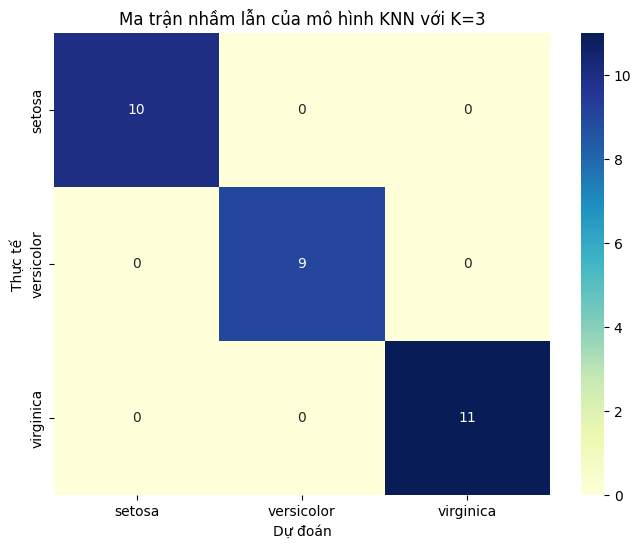

In [1]:
# K-NN
# Phân loại loài hoa iris bằng KNN
# Thư viện
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Tải dữ liệu Iris
# (bao gồm 150 mẫu với 4 đặc trưng là chiều dài,chiều rộng đài hoa và chiều dài chiều rộng cánh hoa)
# 3 loại hoa
iris = load_iris()
X = iris.data # Dữ liệu đặc trưng
y = iris.target # Nhãn mục tiêu

# Chia tập dữ liệu thành tập huấn luyện và tập kiểm tra bao gồm 20 % (30 mẫu) là tập test 80% (120 mẫu) là tập train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

# Xây dựng mô hình KNN và chọn K=3
k = 3 # khi mô hình đi xác định giá trị mới thì sẽ kiếm 3 giá trị gần nhất rồi quyết định giá trị mới thuộc loại nào
knn_model = KNeighborsClassifier(n_neighbors=k)
knn_model.fit(X_train, y_train) # Huấn luyện mô hình

# Dự đoán trên tập kiểm tra
y_pred = knn_model.predict(X_test)
#Đánh giá mô hình
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Độ chính xác của mô hình KNN với K={k}: {accuracy:.2f}")
print("Ma trận nhầm lẫn:")
print(conf_matrix)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))
# Ma trận nhầm lẫn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, cmap="YlGnBu", fmt="d",
xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title(f"Ma trận nhầm lẫn của mô hình KNN với K={k}")
plt.show()

Độ chính xác của mô hình SVM: 0.98
Ma trận nhầm lẫn:
[[41  2]
 [ 0 71]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        43
           1       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



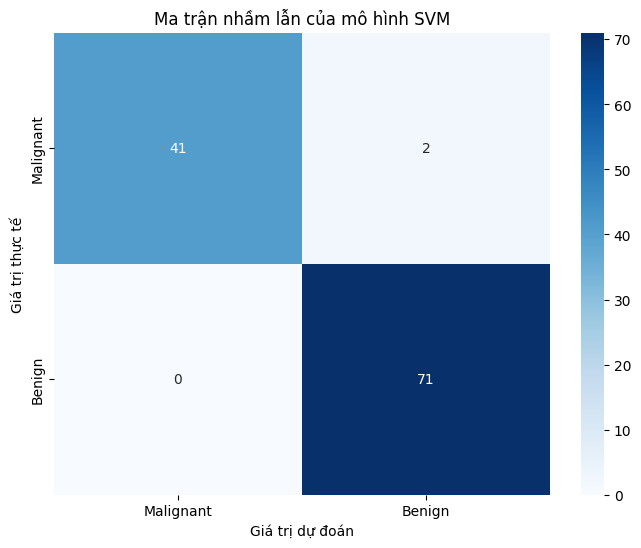

In [3]:
# Thư viện
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Tải bộ dữ liệu Breast Cancer
cancer = datasets.load_breast_cancer()
X = cancer.data # Dữ liệu đặc trưng
y = cancer.target # Nhãn mục tiêu (0: Ác tính, 1: Lành tính)

# Chia dữ liệu thành tập huấn luyện và tập kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Chuẩn hóa dữ liệu (trong bộ dữ liệu thì biên độ giữa các đặc trung khác nhau cần chuẩn hóa)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) #Tính trung bình và độ lệch chuẩn của tập train
X_test = scaler.transform(X_test)# dựa vào độ lệch chuẩn vừa tính

# Xây dựng mô hình SVM với kernel RBF
svm_model = SVC(kernel='rbf', C=1, gamma='scale') # C và gamma là các siêu tham số
svm_model.fit(X_train, y_train) # Huấn luyện mô hình
# Dự đoán trên tập kiểm tra
y_pred = svm_model.predict(X_test)
# Đánh giá mô hình
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Độ chính xác của mô hình SVM: {accuracy:.2f}")
print("Ma trận nhầm lẫn:")
print(conf_matrix)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))
# Trực quan hóa ma trận nhầm lẫn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])



plt.xlabel("Giá trị dự đoán")
plt.ylabel("Giá trị thực tế")
plt.title("Ma trận nhầm lẫn của mô hình SVM")
plt.show()